In [1]:
# 06 - Transfer learning (TP8): ResNet50 and VGG16, pre-trained on ImageNet, on our heart sounds
# (project model 4: "CNN pré-entraîné ResNet18/50", and VGG16 to compare, like the prof's TP)
#
# Transfer learning = we re-use a CNN that already learned to "see" on ImageNet (1 million photos, 1000 classes).
# The course gives 4 ways to use a pre-trained model:
#   1. Classifier: use it as it is -> its 1000 ImageNet classes have no heart sounds, useless for us
#   2. Standalone feature extractor: it turns each image into a list of numbers (the features),
#      then a NEW small model learns on these numbers                                   <- what we do
#   3. Integrated feature extractor: the same thing inside one model, the pre-trained layers frozen
#   4. Weight initialization (fine-tuning): all the layers learn again, with a tiny learning rate
# Why 2: on Windows TensorFlow has no GPU, so training ResNet50 itself (3 or 4) would take hours on our CPU
# (the prof's TP runs on Google Colab with a GPU). With 2, the slow part (ResNet50, VGG16) runs only ONCE per wav.
#
# 1. our Mel spectrograms (made in TP7) -> colour images of 224 x 224 x 3, like the prof's spectrogram images
# 2. ResNet50 and VGG16 (include_top=False) turn each image into a list of numbers
# 3. a small new classifier learns on these numbers, tested on the SAME 3 folds as the other models
# 4. MLflow: one run per pre-trained model, with its final model (pre-trained part + our classifier),
#    and inside it 1 small run per fold, with its training and validation curves (1 point per epoch)

In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"    # hide the TensorFlow info messages

import time
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
import keras
from keras.models import Sequential
from keras.layers import Input, Dense, Dropout, BatchNormalization
from keras.optimizers import Adam

# the pre-trained models (like in the prof's TP), and how each one wants its images prepared
from keras.applications.resnet50 import ResNet50, preprocess_input as resnet_preprocess
from keras.applications.vgg16 import VGG16, preprocess_input as vgg_preprocess

import mlflow
import mlflow.keras

tf.get_logger().setLevel("ERROR")    # hide the "retracing" warnings of TensorFlow

In [3]:
# my folders (the same as in the other notebooks)
project_folder = "D:/MLOps_Project/"
plots_folder = "D:/MLOps_Project/models plots/"    # the figures of the notebooks (saved here, then sent to MLflow)


def load_data(file_name):
    with open(file_name, "rb") as f:
        return pickle.load(f)


def save_data(data, file_name):
    with open(file_name, "wb") as f:
        pickle.dump(data, f)

In [4]:
# the Mel spectrograms made by the CNN notebook (04): the same clean wavs, 5 s, 2000 Hz, 40 bands x 157 moments
spectrograms = load_data(project_folder + "cnn_spectrograms.data")
labels = load_data(project_folder + "cnn_labels.data")

X = np.array(spectrograms)    # (number of wavs, 40, 157), in dB (from -80 to 0)
y = np.array(labels)          # 1 = abnormal, 0 = normal
print("X:", X.shape, "| normal:", np.sum(y == 0), "| abnormal:", np.sum(y == 1))

X: (3681, 40, 157) | normal: 2855 | abnormal: 826


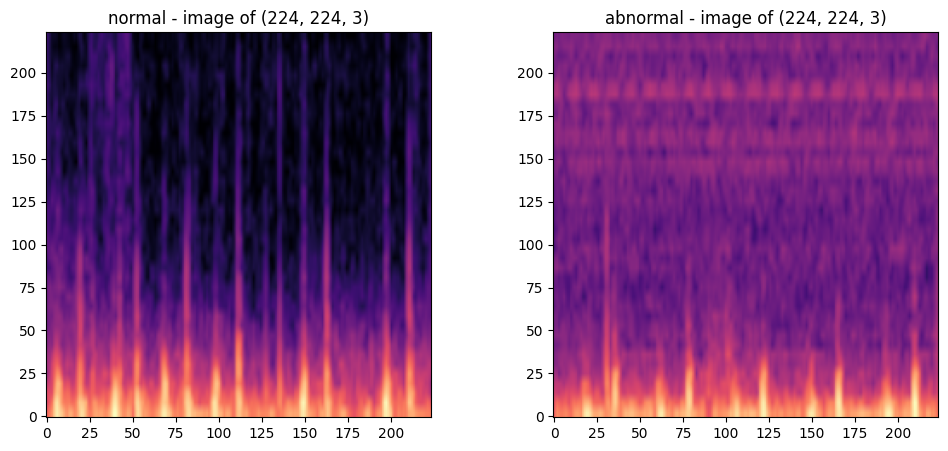

In [5]:
# ==================== 1. From a spectrogram to an "ImageNet" image ====================
# The ImageNet models learned on colour photos: 224 x 224 pixels, 3 colours (red, green, blue) from 0 to 255.
# Like the prof's images: his spectrograms are drawn by librosa (specshow) with the "magma" colours.
# (his images are 480 x 640: 6 times more pixels than 224 x 224 -> 6 times slower on our CPU)
#
# plt.cm.magma() gives a colour to each number from 0 to 1 (0 = black, 0.5 = pink, 1 = light yellow),
# as 4 numbers (red, green, blue, transparency): [..., :3] keeps red, green, blue
def make_images(S):
    images = plt.cm.magma((S + 80) / 80)[..., :3] * 255    # dB (-80 to 0) -> 0 to 1 -> colours from 0 to 255
    images = tf.image.resize(images, (224, 224)).numpy()   # (n, 40, 157, 3) -> (n, 224, 224, 3): stretched
    return images


# what the pre-trained models will see: 1 normal and 1 abnormal wav
examples = make_images(np.array([X[y == 0][0], X[y == 1][0]]))
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(examples[0] / 255, origin="lower")    # / 255: imshow wants the colours from 0 to 1
plt.title("normal - image of " + str(examples[0].shape))
plt.subplot(1, 2, 2)
plt.imshow(examples[1] / 255, origin="lower")
plt.title("abnormal - image of " + str(examples[1].shape))
plt.show()

In [6]:
# ==================== 2. The pre-trained models turn each image into numbers (the features) ====================
# like the prof's TP: a list of models and their names (we could add more: VGG19, MobileNet, InceptionV3, ...)
all_deep_models = [ResNet50, VGG16]
all_model_name_txt = ["ResNet50", "VGG16"]
all_preprocess = [resnet_preprocess, vgg_preprocess]    # each model wants its images prepared like on ImageNet

base_models = {}    # the pre-trained part of each model (we need it again at the end, for the final model)
features = {}       # the numbers of each wav, for each model


def extract_features(base_model, preprocess):
    # 32 images at a time (all the images at once would need ~2 GB of memory)
    all_features = []
    for start in range(0, len(X), 32):
        images = preprocess(make_images(X[start:start + 32]))
        all_features.append(base_model.predict(images, verbose=0))
    return np.concatenate(all_features)


for i in range(len(all_deep_models)):
    model_name_txt = all_model_name_txt[i]
    # weights="imagenet": the weights learned on ImageNet (downloaded the first time: ~95 MB for ResNet50,
    #                     ~60 MB for VGG16, then kept in .keras/models/ like the course says)
    # include_top=False: WITHOUT the last layers (its 1000 ImageNet classes), like in the course
    # pooling="avg": a GlobalAveragePooling2D at the end (like the prof): 1 number per feature map
    base_model = all_deep_models[i](weights="imagenet", include_top=False, pooling="avg", input_shape=(224, 224, 3))
    base_model.trainable = False    # frozen: its ImageNet weights never change
    base_models[model_name_txt] = base_model

    # the slow part (a few minutes): done once, then saved like the other features of the project
    # (to make them again, delete the .data file)
    file_name = project_folder + "tl_features_" + model_name_txt + ".data"
    if os.path.exists(file_name):
        features[model_name_txt] = np.array(load_data(file_name))
    else:
        start_time = time.time()
        features[model_name_txt] = extract_features(base_model, all_preprocess[i])
        save_data(features[model_name_txt], file_name)
        print(model_name_txt, ": features made in", round(time.time() - start_time), "s")
    print(model_name_txt, ":", len(base_model.layers), "layers,", base_model.count_params(), "weights (all frozen)",
          "-> each wav = a list of", features[model_name_txt].shape[1], "numbers")

ResNet50 : 176 layers, 23587712 weights (all frozen) -> each wav = a list of 2048 numbers


VGG16 : 20 layers, 14714688 weights (all frozen) -> each wav = a list of 512 numbers


In [7]:
# ==================== 3. Our new small classifier: it learns on the features ====================
# like the end of the prof's model (BatchNormalization, Dense, Dropout, 1 neuron with sigmoid), but smaller:
# we have only ~2450 train wavs per fold, a big classifier (Dense 1024 + 512 + 128) would learn them by heart
def build_head(n_features):
    model = Sequential()
    model.add(Input(shape=(n_features,)))        # the features of 1 wav (2048 numbers for ResNet50, 512 for VGG16)
    model.add(BatchNormalization())               # puts the features on the same scale (like StandardScaler in TP3)
    model.add(Dense(128, activation="relu"))      # 128 neurons combine the features
    model.add(Dropout(0.5))                       # switches off 50% of the neurons while training -> less overfitting
    model.add(Dense(1, activation="sigmoid"))     # 1 neuron: the probability that the heart is abnormal

    # Adam with learning_rate=0.0001 (10 x smaller than TP7): the features are already good, so with 0.001
    # the classifier learns the train wavs by heart in a few epochs (overfitting: the test loss goes up).
    # Only this NEW small model learns.
    # (the prof's 0.000001 is for fine-tuning: tiny changes to the pre-trained layers themselves)
    model.compile(optimizer=Adam(learning_rate=0.0001), loss="binary_crossentropy", metrics=["accuracy"])
    return model


build_head(2048).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ batch_normalization             │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 270,593 (1.03 MB)

 Trainable params: 266,497 (1.02 MB)

 Non-trainable params: 4,096 (16.00 KB)

In [8]:
# like plot_acc_loss() of the prof: accuracy and loss after each epoch, train vs validation, for the 3 folds
def plot_acc_loss(histories, model_name_txt):
    plt.figure(figsize=(15, 8))
    for fold in range(3):
        h = histories[fold].history
        plt.subplot(2, 3, fold + 1)          # row 1: the accuracy
        plt.plot(h["accuracy"], label="train")
        plt.plot(h["val_accuracy"], label="validation")
        plt.title(model_name_txt + " - Fold " + str(fold + 1) + " - accuracy")
        plt.xlabel("epoch")
        plt.legend()
        plt.subplot(2, 3, fold + 4)          # row 2: the loss
        plt.plot(h["loss"], label="train")
        plt.plot(h["val_loss"], label="validation")
        plt.title(model_name_txt + " - Fold " + str(fold + 1) + " - loss")
        plt.xlabel("epoch")
        plt.legend()
    plt.tight_layout()
    plt.savefig(plots_folder + "tp8_" + model_name_txt + "_curves.png")
    plt.show()

==================== ResNet50 - Fold 1


[[869  68]
 [ 53 237]]
              precision    recall  f1-score   support

      normal       0.94      0.93      0.93       937
    abnormal       0.78      0.82      0.80       290

    accuracy                           0.90      1227
   macro avg       0.86      0.87      0.87      1227
weighted avg       0.90      0.90      0.90      1227

==================== ResNet50 - Fold 2


[[881  81]
 [ 55 210]]
              precision    recall  f1-score   support

      normal       0.94      0.92      0.93       962
    abnormal       0.72      0.79      0.76       265

    accuracy                           0.89      1227
   macro avg       0.83      0.85      0.84      1227
weighted avg       0.89      0.89      0.89      1227

==================== ResNet50 - Fold 3


[[860  96]
 [ 57 214]]
              precision    recall  f1-score   support

      normal       0.94      0.90      0.92       956
    abnormal       0.69      0.79      0.74       271

    accuracy                           0.88      1227
   macro avg       0.81      0.84      0.83      1227
weighted avg       0.88      0.88      0.88      1227



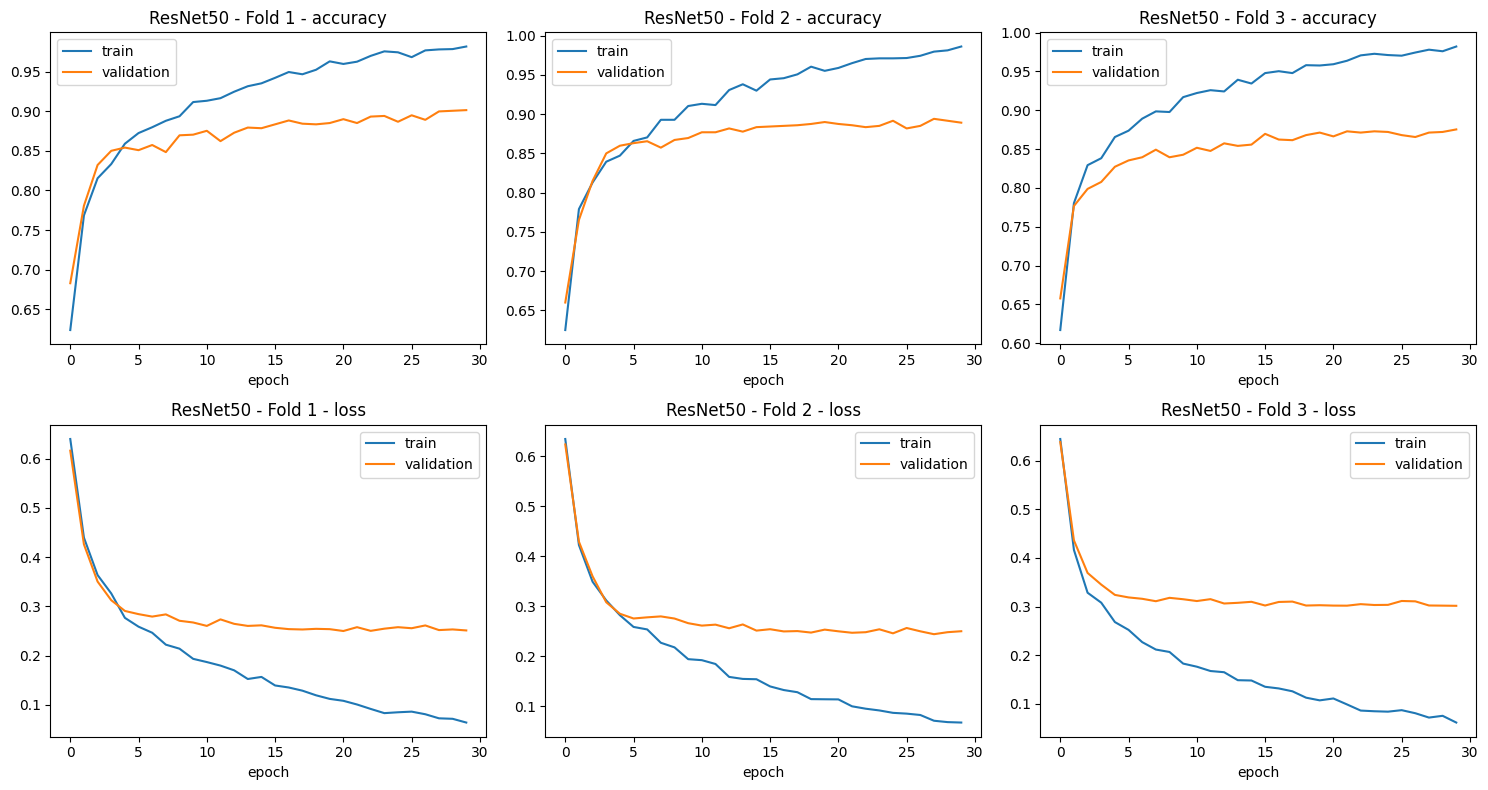

==================== VGG16 - Fold 1


[[807 130]
 [ 53 237]]
              precision    recall  f1-score   support

      normal       0.94      0.86      0.90       937
    abnormal       0.65      0.82      0.72       290

    accuracy                           0.85      1227
   macro avg       0.79      0.84      0.81      1227
weighted avg       0.87      0.85      0.86      1227

==================== VGG16 - Fold 2


[[842 120]
 [ 49 216]]
              precision    recall  f1-score   support

      normal       0.95      0.88      0.91       962
    abnormal       0.64      0.82      0.72       265

    accuracy                           0.86      1227
   macro avg       0.79      0.85      0.81      1227
weighted avg       0.88      0.86      0.87      1227

==================== VGG16 - Fold 3


[[811 145]
 [ 55 216]]
              precision    recall  f1-score   support

      normal       0.94      0.85      0.89       956
    abnormal       0.60      0.80      0.68       271

    accuracy                           0.84      1227
   macro avg       0.77      0.82      0.79      1227
weighted avg       0.86      0.84      0.84      1227



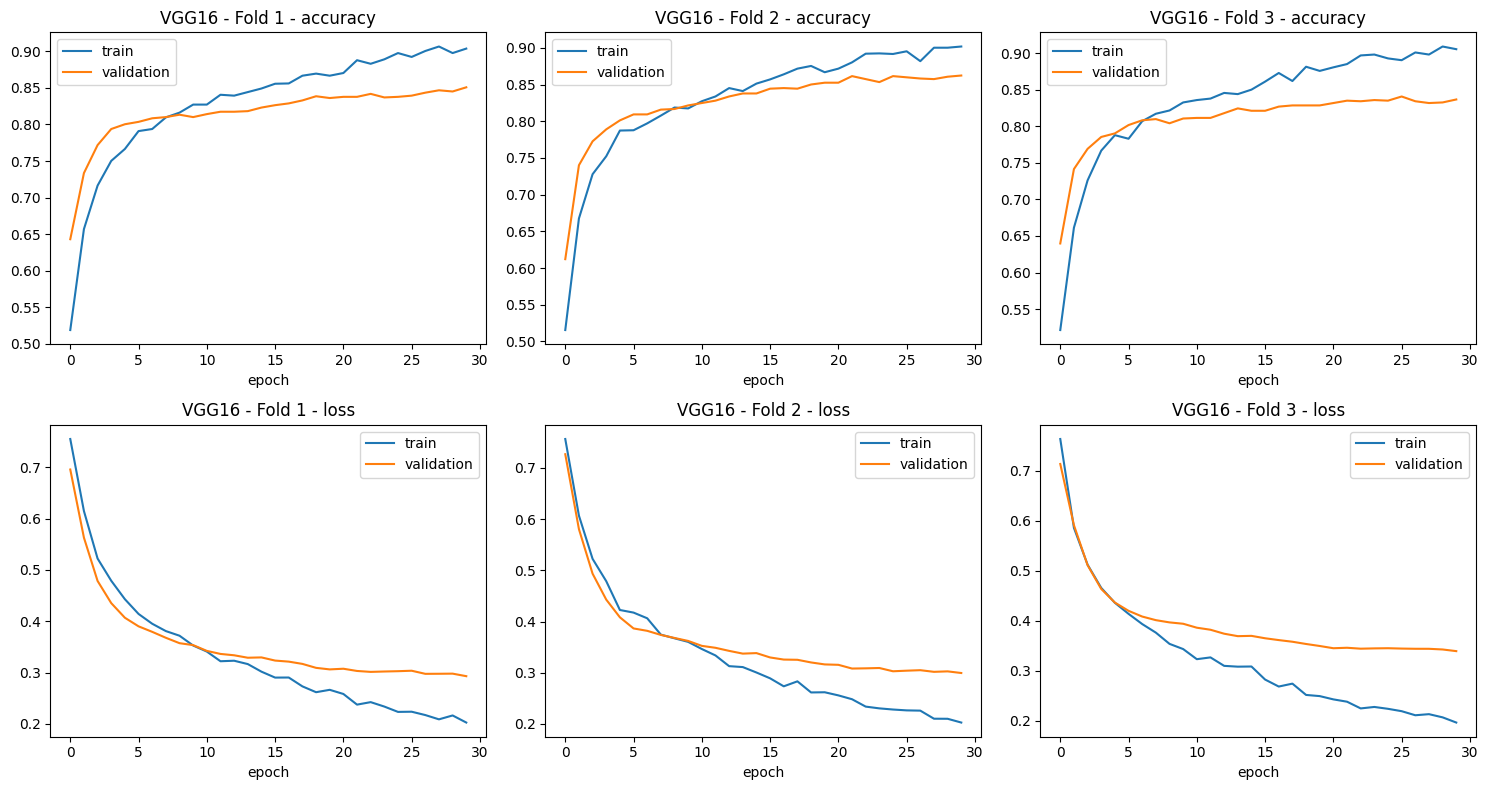

In [9]:
# ==================== 4. Training and testing on 3 folds (the same folds as all the other models) ====================
# No leakage: the pre-trained part never learns from our wavs, so making the features of ALL the wavs
# before the folds is OK. Only the small classifier learns, on the train part of each fold.
EPOCHS = 30         # 30 passes over the train wavs (it's fast: the classifier is small)
BATCH_SIZE = 32     # the weights change after every 32 wavs
class_weight = {0: len(y) / (2 * np.sum(y == 0)), 1: len(y) / (2 * np.sum(y == 1))}    # like TP7: abnormal x 3.5

kfold = KFold(n_splits=3, shuffle=True, random_state=1)    # the same 3 folds as TP3, TP4 and TP7
results = []          # 1 line per (model, fold)
all_histories = {}    # the 3 Keras histories (curves) of each model, kept for MLflow
for model_name_txt in all_model_name_txt:
    F = features[model_name_txt]
    histories = []
    fold = 1
    for train_index, test_index in kfold.split(F):
        print("====================", model_name_txt, "- Fold", fold)
        keras.utils.set_random_seed(0)    # the same random start each time -> the same results if we run it again
        head = build_head(F.shape[1])
        history = head.fit(F[train_index], y[train_index], epochs=EPOCHS, batch_size=BATCH_SIZE,
                           class_weight=class_weight, validation_data=(F[test_index], y[test_index]), verbose=0)
        histories.append(history)

        # the sigmoid gives a probability: more than 0.5 -> abnormal (1), else normal (0)
        y_test = y[test_index]
        y_pred = (head.predict(F[test_index], verbose=0) > 0.5).astype(int).ravel()
        print(confusion_matrix(y_test, y_pred))
        print(classification_report(y_test, y_pred, target_names=["normal", "abnormal"]))
        results.append({
            "model": model_name_txt,
            "fold": fold,
            "accuracy": accuracy_score(y_test, y_pred),
            "precision": precision_score(y_test, y_pred),    # precision, recall, f1: of the abnormal class
            "recall": recall_score(y_test, y_pred),
            "f1": f1_score(y_test, y_pred),
        })
        fold = fold + 1
    plot_acc_loss(histories, model_name_txt)
    all_histories[model_name_txt] = histories

In [10]:
table = pd.DataFrame(results)
print(table.round(3))
print()
print("Mean of the 3 folds:")
print(table.groupby("model")[["accuracy", "precision", "recall", "f1"]].mean().round(3))

      model  fold  accuracy  precision  recall     f1
0  ResNet50     1     0.901      0.777   0.817  0.797
1  ResNet50     2     0.889      0.722   0.792  0.755
2  ResNet50     3     0.875      0.690   0.790  0.737
3     VGG16     1     0.851      0.646   0.817  0.721
4     VGG16     2     0.862      0.643   0.815  0.719
5     VGG16     3     0.837      0.598   0.797  0.684

Mean of the 3 folds:
          accuracy  precision  recall     f1
model                                       
ResNet50     0.889      0.730    0.80  0.763
VGG16        0.850      0.629    0.81  0.708


In [11]:
# ==================== 5. MLflow (Service 6): one run per pre-trained model ====================
# the server and our experiment (the MLflow container must be running: docker start mlflow-server)
mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("audio_benchmark")    # the same experiment as the SVM, the tree and the CNN

for model_name_txt in all_model_name_txt:
    F = features[model_name_txt]
    model_results = table[table["model"] == model_name_txt]    # the 3 folds of this model

    with mlflow.start_run(run_name=model_name_txt.lower()):    # "resnet50" or "vgg16"
        # 1. params = the settings we chose
        mlflow.log_param("model", model_name_txt)
        mlflow.log_param("features", "mel spectrogram 40 x 157 -> magma image 224 x 224 x 3")
        mlflow.log_param("transfer_learning", "feature extractor (ImageNet weights, frozen)")
        mlflow.log_param("classifier", "BatchNormalization + Dense 128 + Dropout 0.5 + Dense 1")
        mlflow.log_param("optimizer", "adam")
        mlflow.log_param("learning_rate", 0.0001)
        mlflow.log_param("epochs", EPOCHS)
        mlflow.log_param("batch_size", BATCH_SIZE)
        mlflow.log_param("n_folds", 3)

        # 2. metrics = the mean of the 3 folds (the same names as the other runs, to compare them)
        for metric in ["accuracy", "precision", "recall", "f1"]:
            mlflow.log_metric("mean_" + metric, model_results[metric].mean())
        for r in results:
            if r["model"] == model_name_txt:
                mlflow.log_metric("fold_accuracy", r["accuracy"], step=r["fold"])
                mlflow.log_metric("fold_recall", r["recall"], step=r["fold"])

        # 3. artifacts = the figure of this model
        mlflow.log_artifact(plots_folder + "tp8_" + model_name_txt + "_curves.png")

        # 4. the model. The 3 folds were only to MEASURE: the classifier we keep learns from ALL the wavs,
        # then we put it after the pre-trained part -> ONE model: image -> probability of "abnormal"
        # (its input = the image made by make_images() and then preprocess_input(), like in step 2)
        keras.utils.set_random_seed(0)
        head = build_head(F.shape[1])
        head.fit(F, y, epochs=EPOCHS, batch_size=BATCH_SIZE, class_weight=class_weight, verbose=0)
        final_model = Sequential([Input(shape=(224, 224, 3)), base_models[model_name_txt], head])
        mlflow.keras.log_model(final_model, "model")    # ~100 MB for ResNet50, ~60 MB for VGG16

        # 5. the 3 folds: 1 small run per fold INSIDE this run (nested=True), with its curves and its results
        for r in results:
            if r["model"] == model_name_txt:
                fold = r["fold"]
                h = all_histories[model_name_txt][fold - 1].history    # what Keras saved after each epoch
                with mlflow.start_run(run_name=model_name_txt.lower() + "_fold" + str(fold), nested=True):
                    mlflow.log_param("fold", fold)
                    # training vs validation: 1 point per epoch -> MLflow draws the curves (tab "Model metrics")
                    for epoch in range(EPOCHS):
                        mlflow.log_metric("train_loss", h["loss"][epoch], step=epoch + 1)
                        mlflow.log_metric("val_loss", h["val_loss"][epoch], step=epoch + 1)
                        mlflow.log_metric("train_accuracy", h["accuracy"][epoch], step=epoch + 1)
                        mlflow.log_metric("val_accuracy", h["val_accuracy"][epoch], step=epoch + 1)
                    # the results on the validation wavs of this fold (val_accuracy = the last point of its curve)
                    mlflow.log_metric("val_precision", r["precision"])
                    mlflow.log_metric("val_recall", r["recall"])
                    mlflow.log_metric("val_f1", r["f1"])
    print(model_name_txt, ": final model saved in MLflow")

2026/11/22 17:05:52 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.


2026/11/22 17:06:49 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


🏃 View run resnet50_fold1 at: http://localhost:5000/#/experiments/1/runs/174355e494b944d8bce857ea141f2d0b
🧪 View experiment at: http://localhost:5000/#/experiments/1


🏃 View run resnet50_fold2 at: http://localhost:5000/#/experiments/1/runs/e231023cd52b456b98179916dce816be
🧪 View experiment at: http://localhost:5000/#/experiments/1


🏃 View run resnet50_fold3 at: http://localhost:5000/#/experiments/1/runs/54bd6f9251f44ec0b4ba6a2ebc23c704
🧪 View experiment at: http://localhost:5000/#/experiments/1


🏃 View run resnet50 at: http://localhost:5000/#/experiments/1/runs/7622acb8fec7411e80fe0a0c9f28f44c
🧪 View experiment at: http://localhost:5000/#/experiments/1


... (4 outputs left out)

🏃 View run vgg16_fold2 at: http://localhost:5000/#/experiments/1/runs/a114e2a1649a47af8e379511c88bb10c
🧪 View experiment at: http://localhost:5000/#/experiments/1


🏃 View run vgg16_fold3 at: http://localhost:5000/#/experiments/1/runs/247ccb699546436f92b0ac7d8edc440c
🧪 View experiment at: http://localhost:5000/#/experiments/1


🏃 View run vgg16 at: http://localhost:5000/#/experiments/1/runs/d53207c8802145608797ed6701a26fe3
🧪 View experiment at: http://localhost:5000/#/experiments/1


VGG16 : final model saved in MLflow


In [12]:
# All the runs of the experiment (SVM, tree, CNN and now ResNet50 and VGG16), the highest recall first:
# the project keeps the model with the highest recall of abnormal (the sick hearts)
runs = mlflow.search_runs(experiment_names=["audio_benchmark"])
runs = runs[runs["metrics.mean_recall"].notna()]    # only the main runs (the fold runs inside them have no mean_recall)
columns = ["tags.mlflow.runName", "params.model", "params.features", "metrics.mean_recall",
           "metrics.mean_f1", "metrics.mean_precision", "metrics.mean_accuracy"]
runs[columns].sort_values("metrics.mean_recall", ascending=False).round(3)

,tags.mlflow.runName,params.model,params.features,metrics.mean_recall,metrics.mean_f1,metrics.mean_precision,metrics.mean_accuracy
41,cnn,CNN,"mel spectrogram 40 x 157 (5 s, 2000 Hz)",0.925,0.655,0.510,0.778
42,svm_rbf_2s,SVM,mel spectrogram flatten (30 bands),0.836,0.638,0.516,0.787
27,svm_rbf_2s,SVM,mel spectrogram flatten (30 bands),0.836,0.638,0.516,0.787
39,svm_rbf_5s,SVM,mel spectrogram flatten (30 bands),0.829,0.639,0.521,0.791
16,svm_rbf_5s,SVM,mel spectrogram flatten (30 bands),0.829,0.639,0.521,0.791
11,vgg16,VGG16,mel spectrogram 40 x 157 -> magma image 224 x ...,0.810,0.708,0.629,0.850
4,svm_rbf_10s,SVM,mel spectrogram flatten (30 bands),0.809,0.639,0.528,0.795
37,svm_rbf_10s,SVM,mel spectrogram flatten (30 bands),0.809,0.639,0.528,0.795
23,resnet50,ResNet50,mel spectrogram 40 x 157 -> magma image 224 x ...,0.800,0.763,0.730,0.889
36,decision_tree_gini_depth10,DecisionTree,MFCC mean + std (26),0.718,0.629,0.559,0.810
